# San Diego Airbnb Price Prediction Project

**Team Members:** Andy Huang and Cole Tamashiro

This project uses the San Diego Airbnb `listings.csv` dataset to predict Airbnb listing prices. Since price is a number, this is a regression problem.

The code is written in a simple zyBooks-style structure:

1. Import packages
2. Load the dataset
3. Clean the data
4. Create `X` and `y`
5. Split into training and testing data
6. Train regression models
7. Evaluate and compare the models


## 1. Import packages

This cell imports the packages used in the project. The main tools are pandas for data, matplotlib for graphs, and sklearn for machine learning models.


In [27]:
# Import packages and functions
import warnings
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics


## 2. Load the dataset

This cell loads the San Diego Airbnb dataset. The file should be in the same folder as this notebook.


In [28]:
# Load the Airbnb dataset
airbnb = pd.read_csv("listings.csv")

# Print the number of rows and columns
print(airbnb.shape)

# Print the first five rows
airbnb.head()


(13162, 79)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,6,https://www.airbnb.com/rooms/6,20250925032747,2025-09-25,city scrape,North Park Craftsmen House * Great for Families,This Beautiful Craftsman house has all the mod...,"We have the best Neighborhood in San Diego, in...",https://a0.muscache.com/pictures/miso/Hosting-...,29,...,4.97,4.80,4.82,"STR-04545L, 631067",f,1,1,0,0,0.96
1,12447,https://www.airbnb.com/rooms/12447,20250925032747,2025-09-25,city scrape,Cozy Pacific Beach Hideaway!,Your San Diego hideaway awaits!<br /><br />Pri...,Quieter area of the busy beach community but w...,https://a0.muscache.com/pictures/hosting/Hosti...,48669,...,5.00,4.86,4.57,"STR-06735L, 631362",f,2,0,2,0,0.04
2,29967,https://www.airbnb.com/rooms/29967,20250925032747,2025-09-25,city scrape,"Great home, 10 min walk to Beach","This 2 bedroom, 2 full bathroom home offers al...","🌴☀️ Welcome to Pacific Beach, California — whe...",https://a0.muscache.com/pictures/76103867/c9b5...,129123,...,4.93,4.85,4.71,"STR-05218L, 645110",f,3,3,0,0,0.70
3,62274,https://www.airbnb.com/rooms/62274,20250925032747,2025-09-25,city scrape,"charming, colorful, close to beach","Modern, cozy, artsy, and european in a lush ga...","We are in walking distance to Starbucks, Trade...",https://a0.muscache.com/pictures/84577734/93ca...,302986,...,4.87,4.87,4.80,"STR-00821L, 520121",f,2,0,2,0,5.47
4,62949,https://www.airbnb.com/rooms/62949,20250925032747,2025-09-25,city scrape,Pacific Beach Cozy Private Hideaway Bikes Incl...,"Cozy Private Beach Retreat. 420 smoking is ok,...","This is the best part of Pacific Beach, we are...",https://a0.muscache.com/pictures/hosting/Hosti...,21532,...,4.95,4.84,4.82,"STR-06358L, 62086",f,4,4,0,0,7.55


## 3. Select useful columns

The full Airbnb dataset has many columns. To keep the project simple, this project only uses columns that are easy to understand and useful for predicting price.


In [29]:
# Select useful columns for the project
airbnb = airbnb[[
    "price",
    "room_type",
    "neighbourhood_cleansed",
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms_text",
    "minimum_nights",
    "number_of_reviews",
    "review_scores_rating",
    "availability_365",
    "host_is_superhost",
    "host_identity_verified",
    "instant_bookable",
    "reviews_per_month"
]]

# Check the selected columns
print(airbnb.shape)
airbnb.head()


(13162, 17)


,price,room_type,neighbourhood_cleansed,latitude,longitude,accommodates,bedrooms,beds,bathrooms_text,minimum_nights,number_of_reviews,review_scores_rating,availability_365,host_is_superhost,host_identity_verified,instant_bookable,reviews_per_month
0,$211.00,Entire home/apt,North Hills,32.755220,-117.128730,7,3.0,6.0,2 baths,1,202,4.84,331,t,t,f,0.96
1,$82.00,Private room,Pacific Beach,32.805330,-117.234000,2,1.0,0.0,1 private bath,6,7,4.86,304,t,t,f,0.04
2,$184.00,Entire home/apt,Pacific Beach,32.807510,-117.257600,6,2.0,3.0,2 baths,4,129,4.76,331,t,t,f,0.70
3,$88.00,Private room,Pacific Beach,32.805830,-117.242440,2,1.0,1.0,1 private bath,1,987,4.79,223,t,t,f,5.47
4,$105.00,Entire home/apt,Pacific Beach,32.806553,-117.234808,2,0.0,0.0,1 bath,1,1203,4.87,182,t,t,f,7.55


## 4. Clean the price column

The `price` column starts as text because it includes dollar signs and commas. This cell removes those symbols and changes the column into numbers.


In [30]:
# Remove dollar signs and commas from price
airbnb["price"] = airbnb["price"].replace(r"[\$,]", "", regex=True)

# Convert price to a number
airbnb["price"] = airbnb["price"].astype(float)

# Check price again
print(airbnb["price"].head())


0    211.0
1     82.0
2    184.0
3     88.0
4    105.0
Name: price, dtype: float64


## 5. Clean the bathroom column

The `bathrooms_text` column is written as text, like "1 bath" or "2.5 baths". This cell extracts the number and saves it as a new `bathrooms` column. 


In [31]:
# Extract the bathroom number from bathrooms_text
airbnb["bathrooms"] = airbnb["bathrooms_text"].str.extract(r"(\d+\.?\d*)")

# Convert bathrooms to a number
airbnb["bathrooms"] = airbnb["bathrooms"].astype(float)

# Drop the old bathroom text column
airbnb = airbnb.drop(columns=["bathrooms_text"])

# Check the new bathrooms column
print(airbnb["bathrooms"].head())


0    2.0
1    1.0
2    2.0
3    1.0
4    1.0
Name: bathrooms, dtype: float64


## 6. Convert true/false columns into numbers

Some columns use `t` and `f`. Machine learning models need numbers, so this cell changes `t` to 1 and `f` to 0.


In [32]:
# Convert true/false columns into 1/0 columns
airbnb["host_is_superhost"] = airbnb["host_is_superhost"].replace({"t": 1, "f": 0})
airbnb["host_identity_verified"] = airbnb["host_identity_verified"].replace({"t": 1, "f": 0})
airbnb["instant_bookable"] = airbnb["instant_bookable"].replace({"t": 1, "f": 0})

# Check the updated columns
airbnb[["host_is_superhost", "host_identity_verified", "instant_bookable"]].head()


,host_is_superhost,host_identity_verified,instant_bookable
0,1,1,0
1,1,1,0
2,1,1,0
3,1,1,0
4,1,1,0


## 7. Remove missing values

Missing values can cause model errors. To keep this project simple, rows with missing values are dropped.


In [33]:
# Check missing values before cleaning
print(airbnb.isna().sum())

# Drop rows with missing values
airbnb = airbnb.dropna()

# Check missing values after cleaning
print(airbnb.isna().sum())
print(airbnb.shape)


price                     1781
room_type                    0
neighbourhood_cleansed       0
latitude                     0
longitude                    0
accommodates                 0
bedrooms                   279
beds                      1780
minimum_nights               0
number_of_reviews            0
review_scores_rating      2200
availability_365             0
host_is_superhost          425
host_identity_verified      33
instant_bookable             0
reviews_per_month         2200
bathrooms                  112
dtype: int64
price                     0
room_type                 0
neighbourhood_cleansed    0
latitude                  0
longitude                 0
accommodates              0
bedrooms                  0
beds                      0
minimum_nights            0
number_of_reviews         0
review_scores_rating      0
availability_365          0
host_is_superhost         0
host_identity_verified    0
instant_bookable          0
reviews_per_month         0
bathrooms   

## 8. Remove extreme prices

Very expensive listings can make the model harder to train. This cell keeps listings with prices above 0 and at most $1000.


In [34]:
# Keep prices greater than 0 and less than or equal to 1000
airbnb = airbnb[airbnb["price"] > 0]
airbnb = airbnb[airbnb["price"] <= 1000]

# Check the cleaned price summary
print(airbnb["price"].describe())
print(airbnb.shape)


count    9077.000000
mean      229.298226
std       172.180607
min        11.000000
25%       114.000000
50%       173.000000
75%       286.000000
max      1000.000000
Name: price, dtype: float64
(9077, 17)


## 9. Basic graphs for data exploration

These graphs help us understand the dataset before modeling.


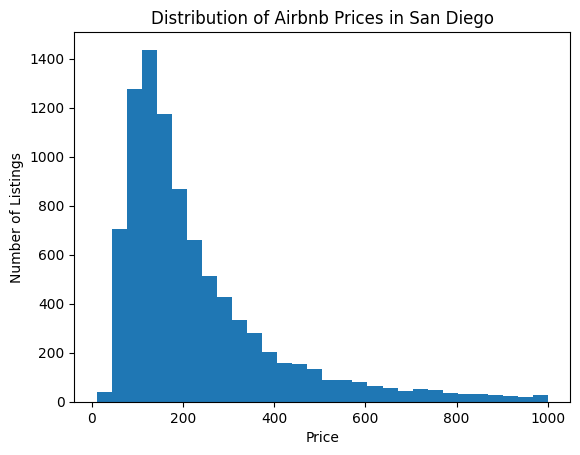

In [35]:
# Graph the distribution of prices
plt.hist(airbnb["price"], bins=30)
plt.xlabel("Price")
plt.ylabel("Number of Listings")
plt.title("Distribution of Airbnb Prices in San Diego")
plt.show()


## 9b. Log transformation of price

The price distribution is right-skewed. Taking the log of price makes the distribution much more normal, which helps the regression models perform better. The graph below shows the distribution after the log transformation.


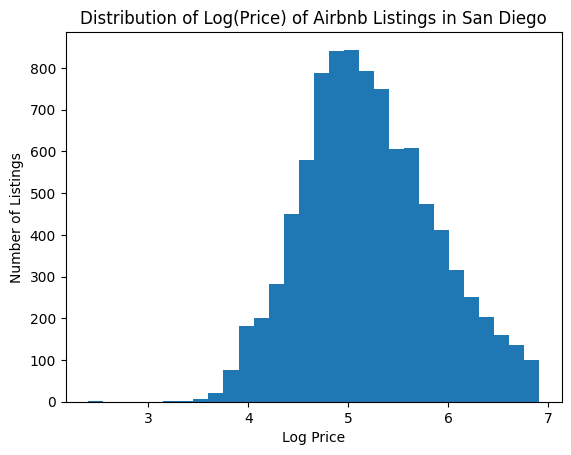

In [36]:
# Create a log price column
airbnb["log_price"] = np.log(airbnb["price"])

# Graph the distribution of log price
plt.hist(airbnb["log_price"], bins=30)
plt.xlabel("Log Price")
plt.ylabel("Number of Listings")
plt.title("Distribution of Log(Price) of Airbnb Listings in San Diego")
plt.show()




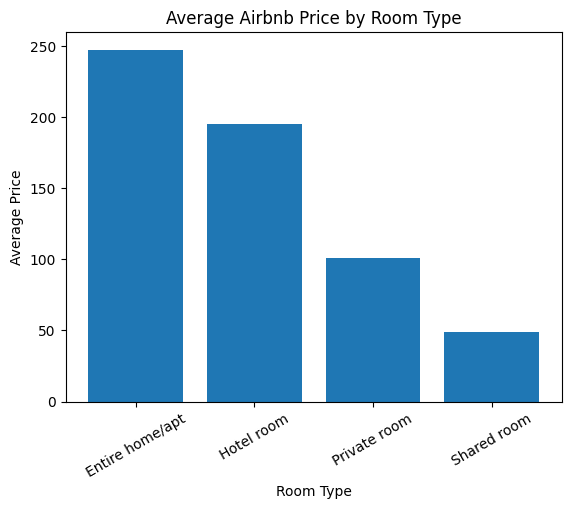

In [37]:
# Calculate average price by room type
roomPrice = airbnb.groupby("room_type")["price"].mean()

# Graph average price by room type
plt.bar(roomPrice.index, roomPrice.values)
plt.xlabel("Room Type")
plt.ylabel("Average Price")
plt.title("Average Airbnb Price by Room Type")
plt.xticks(rotation=30)
plt.show()


## 9c. Correlation heatmap

This heatmap shows how the numerical features correlate with each other and with price. Features closer to 1 or -1 have a stronger relationship with price.


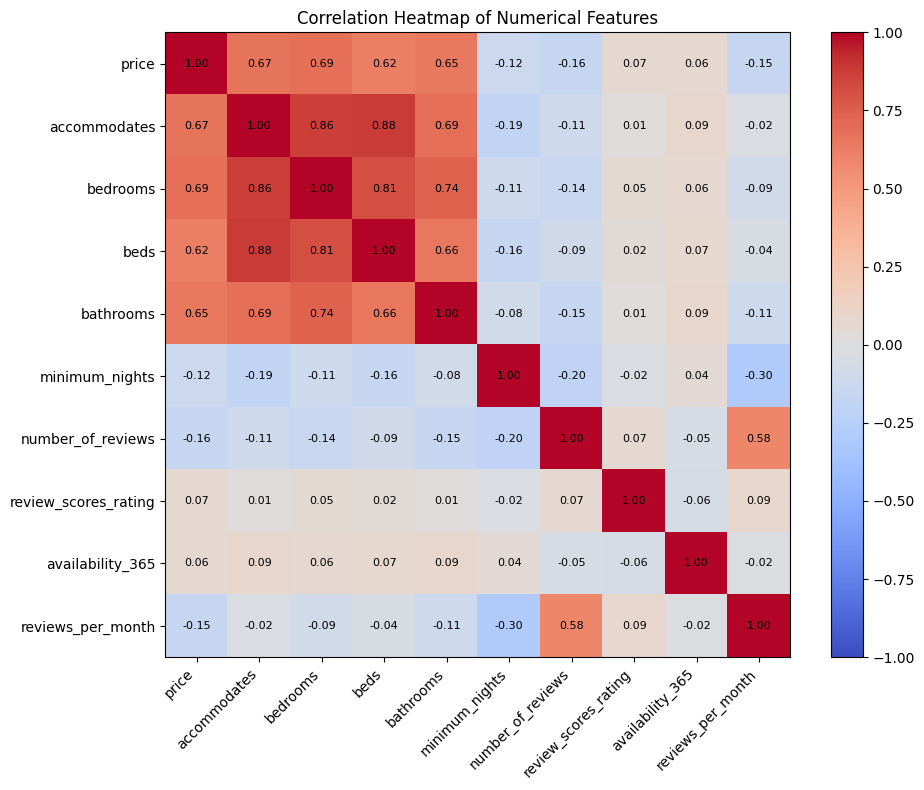

In [38]:
# Select only numerical columns for correlation
numericalCols = [
    "price", "accommodates", "bedrooms", "beds", "bathrooms",
    "minimum_nights", "number_of_reviews", "review_scores_rating",
    "availability_365", "reviews_per_month"
]

# Compute correlation matrix
corrMatrix = airbnb[numericalCols].corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corrMatrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax)

# Add labels
ax.set_xticks(range(len(numericalCols)))
ax.set_yticks(range(len(numericalCols)))
ax.set_xticklabels(numericalCols, rotation=45, ha="right")
ax.set_yticklabels(numericalCols)

# Add correlation values inside each cell
for i in range(len(numericalCols)):
    for j in range(len(numericalCols)):
        ax.text(j, i, f"{corrMatrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

ax.set_title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


## 10. Encode categorical variables

Columns like room type and neighborhood are words. This cell uses dummy variables to turn those categories into numbers.


In [39]:
# Convert categorical columns into dummy variables
airbnb = pd.get_dummies(
    airbnb,
    columns=["room_type", "neighbourhood_cleansed"],
    drop_first=True
)

# Check the new dataset shape
print(airbnb.shape)
airbnb.head()


(9077, 118)


,price,latitude,longitude,accommodates,bedrooms,beds,minimum_nights,number_of_reviews,review_scores_rating,availability_365,...,neighbourhood_cleansed_Terra Nova,neighbourhood_cleansed_Tierrasanta,neighbourhood_cleansed_Tijuana River Valley,neighbourhood_cleansed_Torrey Pines,neighbourhood_cleansed_University City,neighbourhood_cleansed_Valencia Park,neighbourhood_cleansed_Webster,neighbourhood_cleansed_West University Heights,neighbourhood_cleansed_Wooded Area,neighbourhood_cleansed_Yosemite Dr
0,211.0,32.755220,-117.128730,7,3.0,6.0,1,202,4.84,331,...,False,False,False,False,False,False,False,False,False,False
1,82.0,32.805330,-117.234000,2,1.0,0.0,6,7,4.86,304,...,False,False,False,False,False,False,False,False,False,False
2,184.0,32.807510,-117.257600,6,2.0,3.0,4,129,4.76,331,...,False,False,False,False,False,False,False,False,False,False
3,88.0,32.805830,-117.242440,2,1.0,1.0,1,987,4.79,223,...,False,False,False,False,False,False,False,False,False,False
4,105.0,32.806553,-117.234808,2,0.0,0.0,1,1203,4.87,182,...,False,False,False,False,False,False,False,False,False,False


## 11. Define input and output features

`X` contains the input features. `y` contains the output target, which is price.


In [40]:
# Create dataframe X with input features
X = airbnb.drop(columns=["price", "log_price"])

# Create dataframe y with log price as output
y = airbnb[["log_price"]]

# Print the shapes of X and y
print(X.shape)
print(y.shape)


(9077, 116)
(9077, 1)


## 12. Split into training and testing data

The training data teaches the model. The testing data checks how well the model works on listings it has not seen before.


In [41]:
# Set aside 20% of instances for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Print the training and testing shapes
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)


(7261, 116)
(1816, 116)
(7261, 1)
(1816, 1)


## 14. Linear Regression model

Linear Regression is the simplest regression model. It tries to predict price using a straight-line relationship between the features and the target.


In [42]:
# Initialize a linear regression model
airbnbLR = LinearRegression()

# Fit the model to the training data
airbnbLR.fit(X_train, y_train)

# Exponentiate y_train and y_test back to real price scale
y_train_actual = np.exp(y_train)
y_test_actual = np.exp(y_test)

# Training predictions and metrics
airbnbLRTrainPred = airbnbLR.predict(X_train)
airbnbLRTrainPredActual = np.exp(airbnbLRTrainPred)
airbnbLRTrainMAE = metrics.mean_absolute_error(y_train_actual, airbnbLRTrainPredActual)
airbnbLRTrainRMSE = np.sqrt(metrics.mean_squared_error(y_train_actual, airbnbLRTrainPredActual))

# Testing predictions and metrics
airbnbLRPred = airbnbLR.predict(X_test)
airbnbLRPredActual = np.exp(airbnbLRPred)
airbnbLRMAE = metrics.mean_absolute_error(y_test_actual, airbnbLRPredActual)
airbnbLRMSE = metrics.mean_squared_error(y_test_actual, airbnbLRPredActual)
airbnbLRRMSE = np.sqrt(airbnbLRMSE)
airbnbLRR2 = metrics.r2_score(y_test_actual, airbnbLRPredActual)

# Print results
print("Linear Regression Results")
print(f"Train: MAE: {airbnbLRTrainMAE:.2f}  RMSE: {airbnbLRTrainRMSE:.2f}")
print(f"Test:  MAE: {airbnbLRMAE:.2f}  RMSE: {airbnbLRRMSE:.2f}  R²: {airbnbLRR2:.4f}")


Linear Regression Results
Train: MAE: 66.85  RMSE: 113.84
Test:  MAE: 62.27  RMSE: 102.76  R²: 0.6043


## 14b. Linear Regression — Top 10 Coefficients

This graph shows the 10 features with the largest coefficients in the Linear Regression model. Positive coefficients increase the predicted price, negative coefficients decrease it.


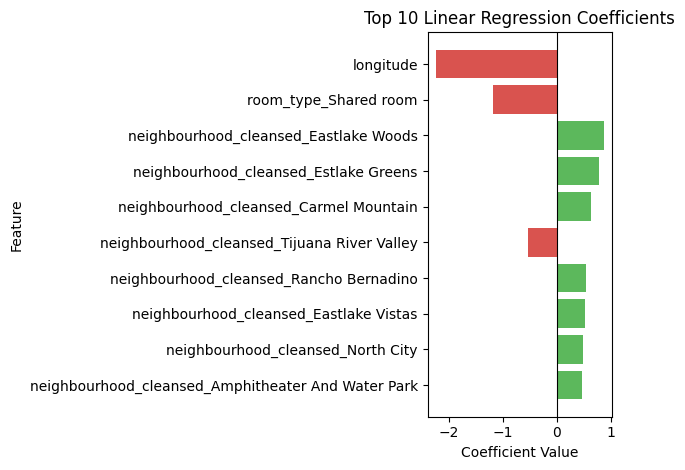

                                           Feature  Coefficient
                                         longitude    -2.244234
                             room_type_Shared room    -1.190351
             neighbourhood_cleansed_Eastlake Woods     0.865209
             neighbourhood_cleansed_Estlake Greens     0.774937
            neighbourhood_cleansed_Carmel Mountain     0.634889
       neighbourhood_cleansed_Tijuana River Valley    -0.544562
           neighbourhood_cleansed_Rancho Bernadino     0.531412
            neighbourhood_cleansed_Eastlake Vistas     0.529138
                 neighbourhood_cleansed_North City     0.485895
neighbourhood_cleansed_Amphitheater And Water Park     0.455200


In [43]:
# Create a dataframe of feature names and their coefficients
lrCoefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": airbnbLR.coef_[0]
})

# Sort by absolute value to find the most impactful features
lrCoefficients["Abs Coefficient"] = lrCoefficients["Coefficient"].abs()
lrCoefficients = lrCoefficients.sort_values(by="Abs Coefficient", ascending=False)

# Get top 10
top10LR = lrCoefficients.head(10)

# Graph top 10 coefficients
colors = ["#d9534f" if c < 0 else "#5cb85c" for c in top10LR["Coefficient"]]
plt.barh(top10LR["Feature"], top10LR["Coefficient"], color=colors)
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.title("Top 10 Linear Regression Coefficients")
plt.axvline(x=0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Print top 10
print(top10LR[["Feature", "Coefficient"]].to_string(index=False))


## 14c. Linear Regression — Actual vs Predicted

This scatter plot compares the actual prices against the predicted prices from the Linear Regression model. A perfect model would have all points on the diagonal line.


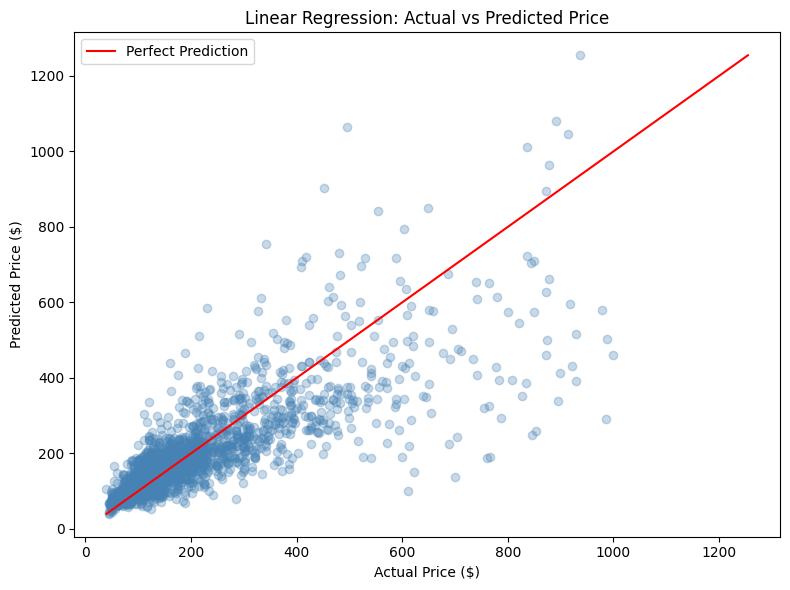

In [44]:
# Actual vs Predicted scatter plot for Linear Regression
plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual, airbnbLRPredActual, alpha=0.3, color="steelblue")

# Draw the perfect prediction line
minVal = min(y_test_actual.min().item(), airbnbLRPredActual.min())
maxVal = max(y_test_actual.max().item(), airbnbLRPredActual.max())
plt.plot([minVal, maxVal], [minVal, maxVal], color="red", linewidth=1.5, label="Perfect Prediction")

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Linear Regression: Actual vs Predicted Price")
plt.legend()
plt.tight_layout()
plt.show()


## 15. Linear Regression cross-validation

Cross-validation checks the model multiple times on different parts of the training data.


In [45]:
# Fit the model with 5-fold cross-validation
cv_results = cross_validate(
    airbnbLR, X_train, np.ravel(y_train), cv=5, scoring="r2"
)

# Print the R-squared score for each fold
print("Test score:", cv_results["test_score"])

# Print average cross-validation score
print("Average test score:", cv_results["test_score"].mean())


Test score: [0.69937691 0.70509818 0.70234428 0.69190628 0.69519973]
Average test score: 0.6987850757928138


## 16. Decision Tree Regressor model

A Decision Tree splits the data into smaller groups based on feature values and makes predictions from those splits. It serves as a middle ground between the simple Linear Regression and the more complex Random Forest.


In [46]:
# Initialize the decision tree model with best parameters
airbnbTree = DecisionTreeRegressor(max_depth=8, min_samples_split=10, random_state=42)

# Fit the model to the training data
airbnbTree.fit(X_train, np.ravel(y_train))

# Training predictions and metrics
airbnbTreeTrainPred = airbnbTree.predict(X_train)
airbnbTreeTrainPredActual = np.exp(airbnbTreeTrainPred)
airbnbTreeTrainMAE = metrics.mean_absolute_error(y_train_actual, airbnbTreeTrainPredActual)
airbnbTreeTrainRMSE = np.sqrt(metrics.mean_squared_error(y_train_actual, airbnbTreeTrainPredActual))

# Testing predictions and metrics
airbnbTreePred = airbnbTree.predict(X_test)
airbnbTreePredActual = np.exp(airbnbTreePred)
airbnbTreeMAE = metrics.mean_absolute_error(y_test_actual, airbnbTreePredActual)
airbnbTreeMSE = metrics.mean_squared_error(y_test_actual, airbnbTreePredActual)
airbnbTreeRMSE = np.sqrt(airbnbTreeMSE)
airbnbTreeR2 = metrics.r2_score(y_test_actual, airbnbTreePredActual)

# Print results
print("Decision Tree Results")
print(f"Train  — MAE: {airbnbTreeTrainMAE:.2f}  RMSE: {airbnbTreeTrainRMSE:.2f}")
print(f"Test   — MAE: {airbnbTreeMAE:.2f}  RMSE: {airbnbTreeRMSE:.2f}  R²: {airbnbTreeR2:.4f}")
print(airbnbTree.get_params())


Decision Tree Results
Train  — MAE: 58.12  RMSE: 94.87
Test   — MAE: 65.13  RMSE: 103.36  R²: 0.5997
{'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 8, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


## 16b. Decision Tree Visualization

This graph shows the first 3 levels of the Decision Tree. Each node shows the feature it splits on, the threshold value, and how many samples fall into that branch.


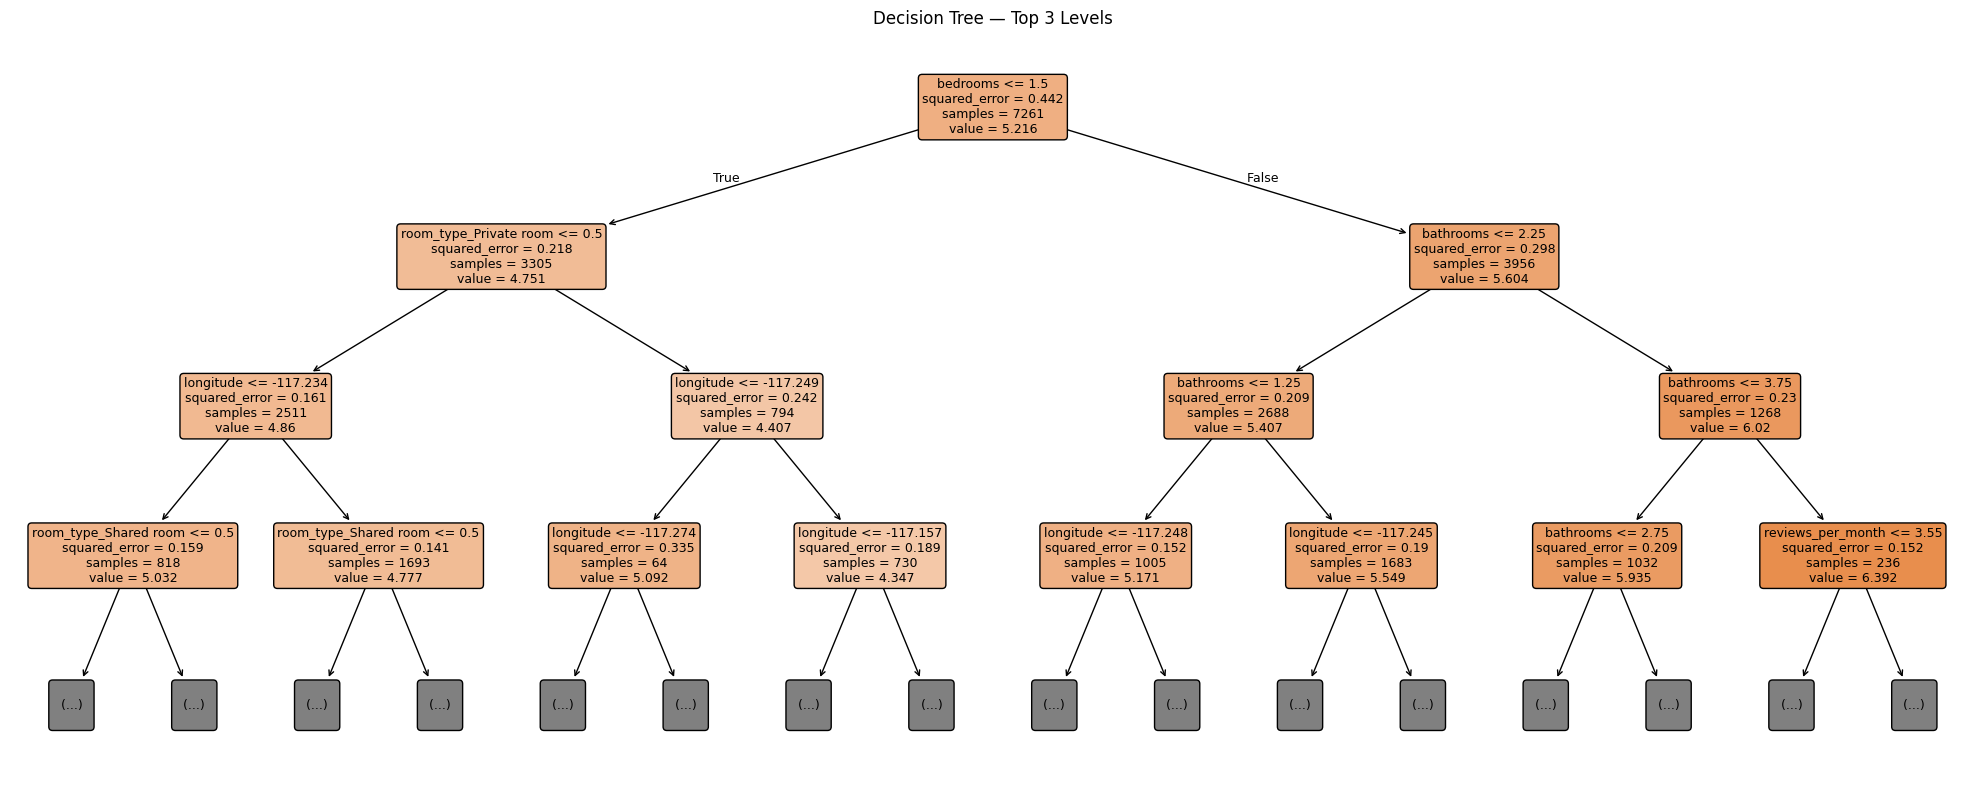

In [47]:
# Visualize the top 3 levels of the decision tree
plt.figure(figsize=(20, 8))
plot_tree(
    airbnbTree,
    max_depth=3,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree — Top 3 Levels")
plt.tight_layout()
plt.show()


## 16c. Actual vs Predicted scatter plot for Decision Tree 

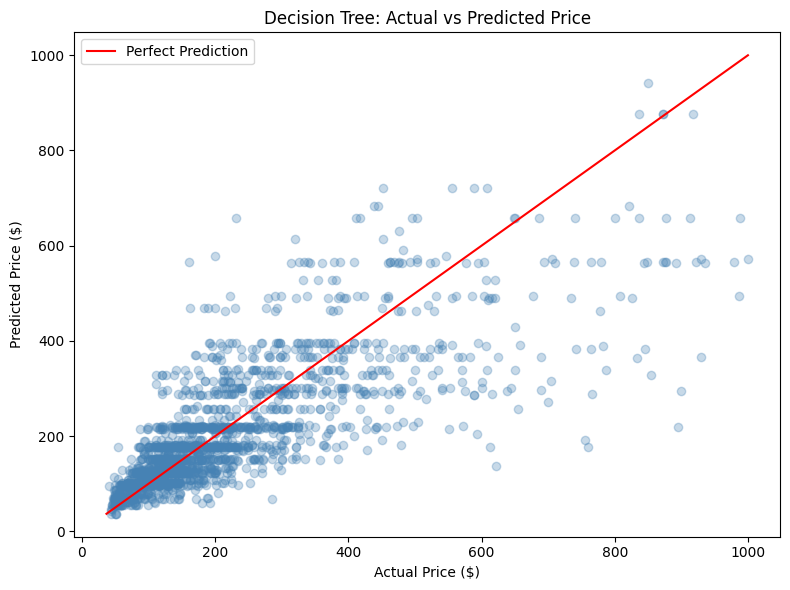

In [48]:
# Actual vs Predicted scatter plot for Decision Tree
plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual, airbnbTreePredActual, alpha=0.3, color="steelblue")

# Draw the perfect prediction line
minVal = min(y_test_actual.min().item(), airbnbTreePredActual.min())
maxVal = max(y_test_actual.max().item(), airbnbTreePredActual.max())
plt.plot([minVal, maxVal], [minVal, maxVal], color="red", linewidth=1.5, label="Perfect Prediction")

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Decision Tree: Actual vs Predicted Price")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Random Forest Regressor model

Random Forest uses many decision trees together. This usually gives better predictions than one tree.


In [49]:
# Initialize a random forest regressor with best parameters
airbnbRF = RandomForestRegressor(n_estimators=200, max_depth=None, random_state=42)

# Fit random forest regressor to X_train and y_train
airbnbRF.fit(X_train, np.ravel(y_train))

# Training predictions and metrics
airbnbRFTrainPred = airbnbRF.predict(X_train)
airbnbRFTrainPredActual = np.exp(airbnbRFTrainPred)
airbnbRFTrainMAE = metrics.mean_absolute_error(y_train_actual, airbnbRFTrainPredActual)
airbnbRFTrainRMSE = np.sqrt(metrics.mean_squared_error(y_train_actual, airbnbRFTrainPredActual))

# Testing predictions and metrics
airbnbRFPred = airbnbRF.predict(X_test)
airbnbRFPredActual = np.exp(airbnbRFPred)
airbnbRFMAE = metrics.mean_absolute_error(y_test_actual, airbnbRFPredActual)
airbnbRFMSE = metrics.mean_squared_error(y_test_actual, airbnbRFPredActual)
airbnbRFRMSE = np.sqrt(airbnbRFMSE)
airbnbRFR2 = metrics.r2_score(y_test_actual, airbnbRFPredActual)

# Print results
print("Random Forest Results")
print(f"Train  — MAE: {airbnbRFTrainMAE:.2f}  RMSE: {airbnbRFTrainRMSE:.2f}")
print(f"Test   — MAE: {airbnbRFMAE:.2f}  RMSE: {airbnbRFRMSE:.2f}  R²: {airbnbRFR2:.4f}")


Random Forest Results
Train  — MAE: 22.83  RMSE: 41.13
Test   — MAE: 55.65  RMSE: 93.21  R²: 0.6745


## 17b. Random Forest — Feature Importance

Feature importance shows which variables had the greatest influence on the model's price predictions. Values add up to 1.0 (100%). Higher values mean the feature explains more of the variation in price.


Top 15 Most Important Features
               Feature  Importance
              bedrooms    0.425350
             bathrooms    0.147323
             longitude    0.096419
     reviews_per_month    0.043902
room_type_Private room    0.040590
          accommodates    0.038314
              latitude    0.038182
  review_scores_rating    0.034858
      availability_365    0.032129
     number_of_reviews    0.026370
        minimum_nights    0.015365
                  beds    0.010484
 room_type_Shared room    0.008588
host_identity_verified    0.003796
     host_is_superhost    0.003684


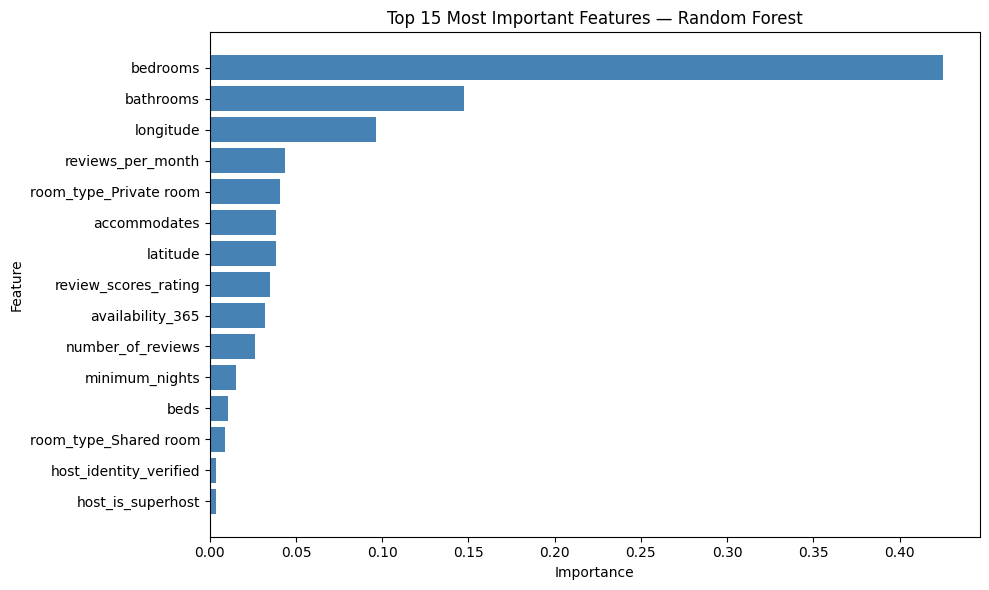

In [50]:
# Create feature importance dataframe
featureImportance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": airbnbRF.feature_importances_
})

# Sort from most to least important
featureImportance = featureImportance.sort_values(by="Importance", ascending=False)

# Print top 15 as a table
print("Top 15 Most Important Features")
print(featureImportance.head(15).to_string(index=False))

# Graph top 15 as a bar chart
top15 = featureImportance.head(15)
plt.figure(figsize=(10, 6))
plt.barh(top15["Feature"], top15["Importance"], color="steelblue")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Most Important Features — Random Forest")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 17c. Actual vs Predicted scatter plot for Random Forest

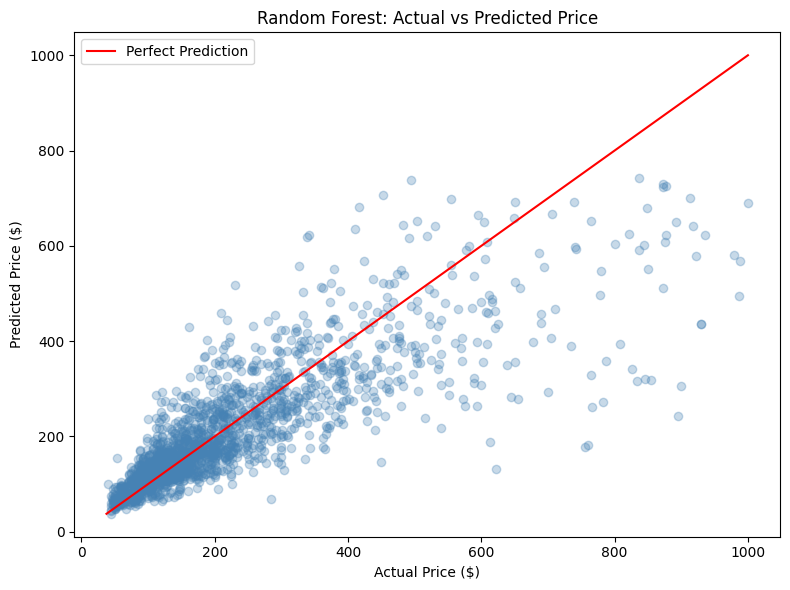

In [53]:
# Actual vs Predicted scatter plot for Random Forest
plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual, airbnbRFPredActual, alpha=0.3, color="steelblue")

# Draw the perfect prediction line
minVal = min(y_test_actual.min().item(), airbnbRFPredActual.min())
maxVal = max(y_test_actual.max().item(), airbnbRFPredActual.max())
plt.plot([minVal, maxVal], [minVal, maxVal], color="red", linewidth=1.5, label="Perfect Prediction")

plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Random Forest: Actual vs Predicted Price")
plt.legend()
plt.tight_layout()
plt.show()

## 18. Compare model results

This table compares the baseline, Linear Regression, Decision Tree, and Random Forest models.

Lower MAE and RMSE are better. Higher R-squared is better.


In [51]:
# Create a dataframe of model results
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "Train MAE": [airbnbLRTrainMAE, airbnbTreeTrainMAE, airbnbRFTrainMAE],
    "Train RMSE": [airbnbLRTrainRMSE, airbnbTreeTrainRMSE, airbnbRFTrainRMSE],
    "Test MAE": [airbnbLRMAE, airbnbTreeMAE, airbnbRFMAE],
    "Test RMSE": [airbnbLRRMSE, airbnbTreeRMSE, airbnbRFRMSE],
    "Test R²": [airbnbLRR2, airbnbTreeR2, airbnbRFR2]
})

# Sort by Test MAE
results = results.sort_values(by="Test MAE")

# Print results
print(results.to_string(index=False))


            Model  Train MAE  Train RMSE  Test MAE  Test RMSE  Test R²
    Random Forest  22.829983   41.129702 55.652619  93.207908 0.674481
Linear Regression  66.850533  113.843234 62.271879 102.763163 0.604319
    Decision Tree  58.117709   94.867554 65.130812 103.356327 0.599738


## 19. Graph the model comparison

This graph compares the models using MAE. The best model should have the lowest MAE.


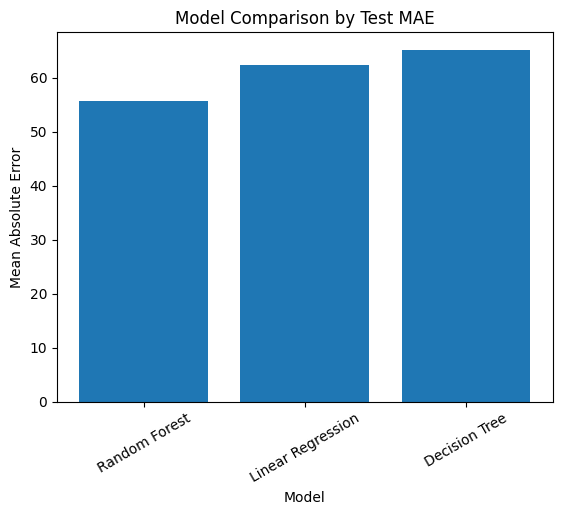

In [52]:
# Graph model comparison by MAE
plt.bar(results["Model"], results["Test MAE"])
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")
plt.title("Model Comparison by Test MAE")
plt.xticks(rotation=30)
plt.show()


## 21. Conclusion

This project built regression models to predict Airbnb prices in San Diego. The models were compared using MAE, MSE, RMSE, and R-squared.

The baseline model gives a simple starting point. Linear Regression is easy to understand, but it may not capture complex patterns. Decision Tree can capture more patterns, but it can overfit. Random Forest usually performs the best because it combines many trees.

The feature importance results help explain which listing features had the biggest effect on price.
